### Feature Set Selection for Wind Offshore Forecasting

This notebook compares six feature-engineering strategies for forecasting the German offshore wind capacity factor. The goal is to select a dataset that provides the best balance between **predictive quality** and **feature complexity**.

The comparison follows four rules:

1. Validation is chronological: every model is trained on the past and evaluated on a later time block.
2. The same folds, models, metrics, and training procedure are used for every dataset.
3. If several datasets are within `0.003` R² of the best mean score, the dataset with fewer features is preferred.

In [1]:
# Core imports
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyrootutils
from IPython.display import display
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from dotenv import load_dotenv
import os

load_dotenv()  # Load environment variables from .env file

# Find the project root and make local modules importable
PROJECT_ROOT = pyrootutils.setup_root(
    search_from=__file__ if "__file__" in locals() else ".",
    indicator=".gitignore",
    pythonpath=True,
)

from utils.utils_for_notebooks import get_available_threads

# Set the path to the datasets directory
DATASETS_DIR = PROJECT_ROOT / "data" / "datasets"

# Automatically determine the number of available threads for computation
N_THREADS = get_available_threads() # Change this to a specific number if needed

# Setting the number of days to hold out for testing
HOLDOUT_DAYS = int(os.getenv("HOLDOUT_DAYS") or 28)  # Default to 28 if not set in .env

# Keep notebook tables compact and readable
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.5f}")

### Loading the candidate datasets

The candidates represent progressively richer descriptions of the same forecast timestamps:

- regional (North / Baltic Sea)mean and standard deviation of `power_proxy`;
- the same regional aggregation with binary risk flags (`cutin_risk` / `cutout_risk` etc.) aggregated by maximum;
- regional statistics plus the 10th, 50th, and 90th `power_proxy` quantiles;
- 14 separate location-level `power_proxy` signals;
- the 14 location-level signals plus regional mean and standard deviation;
- the full location-level representation with additional *u/v* wind components.

UPDATE: 2 interpolated datasets from notebook 1b have been added for comparison:
- **interpolaterd** observations at 14 separate locations **without** T-1 and T+1 deltas;
- **interpolaterd** observations at 14 separate locations **with** T-1 and T+1 deltas (+/- 1 hour, applied only to the nearest actual observations, not to interpolated ones).

All datasets must contain the same target timestamps. The code below loads them through one explicit file map so that adding or removing a candidate requires changing only one place.

In [2]:
# Define the dataset files to load
DATASET_FILES = {
    "mean_std_proxy_only": "offshore_dataset_15m_2024-03-14_to_2026-06-11.parquet",
    "mean_std_proxy_with_risks_max_agg": "offshore_dataset_15m_risks_max_aggregation_2024-03-14_to_2026-06-11.parquet",
    "mean_std_10_50_90_proxy": "offshore_dataset_15m_proxy_with_10_50_90_quantiles_2024-03-14_to_2026-06-11.parquet",
    "separate_14_proxy_points": "offshore_dataset_15m_raw_14_points_proxy_2024-03-14_to_2026-06-11.parquet",
    "separate_14_proxy_points_with_mean_std": "offshore_dataset_15m_raw_14_points_proxy_with_mean_std_2024-03-14_to_2026-06-11.parquet",
    "separate_14_points_with_u_v": "offshore_dataset_15m_raw_14_points_with_u_v_components_2024-03-14_to_2026-06-11.parquet",
    "interpolated_14_proxy_points": "offshore_dataset_15m_interpolated_14_points_proxy_2024-03-14_to_2026-06-11.parquet",
    "interpolated_14_proxy_points_with_t_deltas": "offshore_dataset_15m_interpolated_14_points_proxy_with_t_deltas_2024-03-14_to_2026-06-11.parquet"
}


# Normalize column names to be more readable and model-safe
def normalize_column_names(frame: pd.DataFrame) -> pd.DataFrame:
    # Return a copy with readable, model-safe column names
    frame = frame.copy()
    replacements = {
        "<lambda_0>": "q10",
        "<lambda_1>": "q50",
        "<lambda_2>": "q90",
    }

    normalized = []
    for column in frame.columns:
        name = str(column)
        for old, new in replacements.items():
            name = name.replace(old, new)
        normalized.append(re.sub(r"[^0-9a-zA-Z_]+", "_", name).strip("_"))

    if len(normalized) != len(set(normalized)):
        raise ValueError("Column normalization created duplicate names.")

    frame.columns = normalized
    return frame


datasets = {
    name: normalize_column_names(pd.read_parquet(DATASETS_DIR / file_name))
    for name, file_name in DATASET_FILES.items()
}

# Print the number of rows and columns for each dataset
for name, frame in datasets.items():
    print(f"{name:45s} rows={len(frame):6,d}  columns={frame.shape[1]:3d}")

mean_std_proxy_only                           rows=78,620  columns= 83
mean_std_proxy_with_risks_max_agg             rows=78,620  columns= 83
mean_std_10_50_90_proxy                       rows=78,620  columns=101
separate_14_proxy_points                      rows=78,620  columns=113
separate_14_proxy_points_with_mean_std        rows=78,620  columns=125
separate_14_points_with_u_v                   rows=78,620  columns=233
interpolated_14_proxy_points                  rows=78,620  columns= 45
interpolated_14_proxy_points_with_t_deltas    rows=78,620  columns=113


### Point-in-time integrity and feature definitions

The target is `capacity_factor`. The following fields are deliberately excluded from the model:

- `capacity_factor` — the target itself;
- `capacity` and `gen_wind_off_act` — direct ingredients of the target;
- `dt_run_utc` and `dt_berlin` — absolute timestamps used only for point-in-time checks and splitting.

`lead_time` remains a valid feature because it is known when the weather forecast is issued. The `delta_after` columns are also valid here: they describe the next step of the **already available weather-forecast trajectory**, not future observed generation.

Before training, the next cell verifies that forecast issue times precede their target times and that all candidate datasets contain identical timestamps and targets.

In [3]:
TARGET_COL = "capacity_factor"
ISSUE_TIME_COL = "dt_run_utc"
TARGET_TIME_COL = "dt_berlin"

NON_FEATURE_COLS = {
    ISSUE_TIME_COL,
    TARGET_TIME_COL,
    "capacity",
    "gen_wind_off_act",
    TARGET_COL,
}


def get_feature_columns(frame: pd.DataFrame) -> list[str]:
    # Select numeric predictors while excluding timestamps and target-related fields.
    return [
        column
        for column in frame.columns
        if column not in NON_FEATURE_COLS
        and pd.api.types.is_numeric_dtype(frame[column])
    ]


def prepare_dataset(frame: pd.DataFrame) -> pd.DataFrame:
    # Sort one dataset and enforce the point-in-time assumptions.
    required = {TARGET_COL, ISSUE_TIME_COL, TARGET_TIME_COL, "capacity", "gen_wind_off_act"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    frame = frame.copy()
    frame[ISSUE_TIME_COL] = pd.to_datetime(frame[ISSUE_TIME_COL], utc=True)
    frame[TARGET_TIME_COL] = (
        pd.to_datetime(frame[TARGET_TIME_COL], utc=True)
        .dt.tz_convert("Europe/Berlin")
    )
    frame = frame.sort_values(TARGET_TIME_COL).reset_index(drop=True)

    if frame[TARGET_TIME_COL].duplicated().any():
        raise ValueError("Target timestamps must be unique within each dataset.")

    target_time_utc = frame[TARGET_TIME_COL].dt.tz_convert("UTC")
    if not (frame[ISSUE_TIME_COL] < target_time_utc).all():
        raise ValueError("Every weather forecast must be issued before its target time.")

    feature_columns = get_feature_columns(frame)
    if frame[feature_columns + [TARGET_COL]].isna().any().any():
        raise ValueError("Features and target must not contain missing values.")

    return frame


datasets = {name: prepare_dataset(frame) for name, frame in datasets.items()}

# Adding a holdout period to reserve the last N days for final test
if HOLDOUT_DAYS > 0:
    # Find the maximum target date across all datasets
    max_target_date = datasets[next(iter(datasets))][TARGET_TIME_COL].dt.date.max()
    cutoff_date = max_target_date - pd.Timedelta(days=HOLDOUT_DAYS)
    
    # Filter each dataset to exclude rows with target dates after the cutoff date
    datasets = {
        name: frame[frame[TARGET_TIME_COL].dt.date <= cutoff_date].reset_index(drop=True)
        for name, frame in datasets.items()
    }
    print(f"Holdout applied: last {HOLDOUT_DAYS} days reserved. Evaluation end date: {cutoff_date}")


# Use one candidate as the reference timeline for every fold.
reference_name = next(iter(datasets))
reference = datasets[reference_name]

for name, frame in datasets.items():
    pd.testing.assert_series_equal(
        frame[TARGET_TIME_COL],
        reference[TARGET_TIME_COL],
        check_names=False,
    )
    np.testing.assert_allclose(frame[TARGET_COL], reference[TARGET_COL])

dataset_inventory = pd.DataFrame(
    [
        {
            "dataset": name,
            "rows": len(frame),
            "n_features": len(get_feature_columns(frame)),
            "start": frame[TARGET_TIME_COL].min(),
            "end": frame[TARGET_TIME_COL].max(),
        }
        for name, frame in datasets.items()
    ]
).sort_values("n_features")

display(dataset_inventory)

Holdout applied: last 28 days reserved. Evaluation end date: 2026-05-14


,dataset,rows,n_features,start,end
6,interpolated_14_proxy_points,75932,40,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
0,mean_std_proxy_only,75932,78,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
1,mean_std_proxy_with_risks_max_agg,75932,78,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
2,mean_std_10_50_90_proxy,75932,96,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
3,separate_14_proxy_points,75932,108,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
7,interpolated_14_proxy_points_with_t_deltas,75932,108,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
4,separate_14_proxy_points_with_mean_std,75932,120,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00
5,separate_14_points_with_u_v,75932,228,2024-03-15 00:00:00+01:00,2026-05-14 23:45:00+02:00


### Expanding-window validation

A random split would leak information through strong temporal autocorrelation. Instead, each fold trains on an expanding historical window and validates on the next block of complete calendar days.

I am currently using an **expanding window** method to evaluate the overall performance of the configurations. However, looking ahead, I am leaning towards a **sliding window** approach to ensure the consistency of the weather models.

In [4]:
# Number of folds for time series cross-validation
N_SPLITS = 5

# Function to create standard expanding splits for time series cross-validation
def build_expanding_splits(
    frame: pd.DataFrame,
    n_splits: int = N_SPLITS,
) -> list[tuple[np.ndarray, np.ndarray]]:
    local_days = frame[TARGET_TIME_COL].dt.date
    unique_days = np.array(sorted(local_days.unique()))
    block_size = len(unique_days) // (n_splits + 1)

    if block_size == 0:
        raise ValueError("Not enough calendar days for the requested number of folds.")

    splits = []

    for fold_index in range(n_splits):
        train_days = unique_days[: block_size * (fold_index + 1)]
        validation_days = unique_days[
            block_size * (fold_index + 1): block_size * (fold_index + 2)
        ]

        train_mask = local_days.isin(train_days)
        validation_mask = local_days.isin(validation_days)

        train_index = np.flatnonzero(train_mask.to_numpy())
        validation_index = np.flatnonzero(validation_mask.to_numpy())

        if len(train_index) == 0 or len(validation_index) == 0:
            raise ValueError(f"Fold {fold_index + 1} is empty.")

        splits.append((train_index, validation_index))

    return splits


# Build the time series splits
time_splits = build_expanding_splits(reference)

# Print the time ranges and sizes of each fold
for fold, (train_index, validation_index) in enumerate(time_splits, start=1):
    train_times = reference.iloc[train_index][TARGET_TIME_COL]
    validation_times = reference.iloc[validation_index][TARGET_TIME_COL]
    print(
        f"Fold {fold}: "
        f"train {train_times.min().date()} -> {train_times.max().date()} "
        f"({len(train_index):,} rows) | "
        f"validate {validation_times.min().date()} -> {validation_times.max().date()} "
        f"({len(validation_index):,} rows)"
    )

Fold 1: train 2024-03-15 -> 2024-07-23 (12,572 rows) | validate 2024-07-24 -> 2024-12-01 (12,580 rows)
Fold 2: train 2024-03-15 -> 2024-12-01 (25,152 rows) | validate 2024-12-02 -> 2025-04-11 (12,572 rows)
Fold 3: train 2024-03-15 -> 2025-04-11 (37,724 rows) | validate 2025-04-12 -> 2025-08-20 (12,576 rows)
Fold 4: train 2024-03-15 -> 2025-08-20 (50,300 rows) | validate 2025-08-21 -> 2025-12-29 (12,580 rows)
Fold 5: train 2024-03-15 -> 2025-12-29 (62,880 rows) | validate 2025-12-30 -> 2026-05-09 (12,572 rows)


### Shared boosting models and nested early stopping

LightGBM, XGBoost, and CatBoost are evaluated because the previous baseline notebook showed that they are the strongest model family for this task. Their settings are intentionally moderate and are kept fixed across feature sets.

The outer validation fold must remain untouched until scoring. To avoid using it for early stopping, the most recent 15% of the outer training days form a small inner validation window. The best iteration is found there, and the model is then refitted on the complete outer training set before the outer validation score is calculated.

Temporal folds measure the variability that matters here: performance across different future periods.

In [5]:
MODEL_NAMES = ("LightGBM", "XGBoost", "CatBoost") # Models to evaluate in the cross-validation
RANDOM_SEED = 322                                 # Random seed for reproducibility
MAX_BOOSTING_ROUNDS = 1_000                       # Maximum number of boosting rounds for the models
LEARNING_RATE = 0.03                              # Learning rate for the models
EARLY_STOPPING_ROUNDS = 50                        # Number of rounds to stop early if no improvement
INNER_VALIDATION_FRACTION = 0.15                  # Fraction of data to use for inner validation


# Function to build a model based on the model name
def build_model(
    model_name: str,
    n_estimators: int,
    seed: int = RANDOM_SEED,
):
    # Build one moderately regularized boosting regressor.
    if model_name == "LightGBM":
        import lightgbm as lgb

        return lgb.LGBMRegressor(
            objective="regression",
            metric="rmse",
            boosting_type="gbdt",
            n_estimators=n_estimators,
            learning_rate=LEARNING_RATE,
            num_leaves=20,
            max_depth=5,
            min_child_samples=50,
            subsample=0.8,
            colsample_bytree=0.7,
            subsample_freq=1,
            reg_alpha=0.1,
            reg_lambda=2.0,
            random_state=seed,
            n_jobs=N_THREADS,
            verbose=-1,
        )

    if model_name == "XGBoost":
        import xgboost as xgb

        return xgb.XGBRegressor(
            objective="reg:squarederror",
            eval_metric="rmse",
            n_estimators=n_estimators,
            learning_rate=LEARNING_RATE,
            max_depth=5,
            min_child_weight=50,
            subsample=0.8,
            colsample_bytree=0.7,
            reg_alpha=0.1,
            reg_lambda=2.0,
            random_state=seed,
            n_jobs=N_THREADS,
            verbosity=0,
        )

    if model_name == "CatBoost":
        from catboost import CatBoostRegressor

        return CatBoostRegressor(
            loss_function="RMSE",
            eval_metric="RMSE",
            iterations=n_estimators,
            learning_rate=LEARNING_RATE,
            depth=5,
            min_data_in_leaf=50,
            bootstrap_type="Bernoulli",
            subsample=0.8,
            rsm=0.7,
            l2_leaf_reg=2.0,
            random_seed=seed,
            thread_count=N_THREADS,
            allow_writing_files=False,
            logging_level="Silent",
        )

    raise ValueError(f"Unknown model: {model_name}")



def build_inner_split(
    frame: pd.DataFrame,
    outer_train_index: np.ndarray,
    validation_fraction: float = INNER_VALIDATION_FRACTION,
) -> tuple[np.ndarray, np.ndarray]:
    # Split outer training data chronologically for early stopping.
    outer_train = frame.iloc[outer_train_index]
    local_days = outer_train[TARGET_TIME_COL].dt.date
    unique_days = np.array(sorted(local_days.unique()))
    validation_day_count = max(1, int(np.ceil(len(unique_days) * validation_fraction)))
    inner_validation_days = unique_days[-validation_day_count:]

    inner_validation_mask = local_days.isin(inner_validation_days)
    earliest_inner_issue = outer_train.loc[
        inner_validation_mask, ISSUE_TIME_COL
    ].min()
    outer_target_time_utc = outer_train[TARGET_TIME_COL].dt.tz_convert("UTC")
    inner_train_mask = (
        ~inner_validation_mask
        & outer_target_time_utc.lt(earliest_inner_issue)
    )

    inner_train_index = outer_train_index[np.flatnonzero(inner_train_mask.to_numpy())]
    inner_validation_index = outer_train_index[
        np.flatnonzero(inner_validation_mask.to_numpy())
    ]
    return inner_train_index, inner_validation_index


def find_best_iteration(
    model_name: str,
    X: pd.DataFrame,
    y: pd.Series,
    inner_train_index: np.ndarray,
    inner_validation_index: np.ndarray,
    seed: int,
) -> int:
    # Tune the number of boosting rounds on the inner time window.
    model = build_model(model_name, MAX_BOOSTING_ROUNDS, seed)
    X_train, y_train = X.iloc[inner_train_index], y.iloc[inner_train_index]
    X_valid, y_valid = X.iloc[inner_validation_index], y.iloc[inner_validation_index]

    if model_name == "LightGBM":
        import lightgbm as lgb

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)],
        )
        return max(1, int(model.best_iteration_))

    if model_name == "XGBoost":
        model.set_params(early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
        return max(1, int(model.best_iteration) + 1)

    model.fit(
        X_train,
        y_train,
        eval_set=(X_valid, y_valid),
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        use_best_model=True,
        verbose=False,
    )
    return max(1, int(model.get_best_iteration()) + 1)


def run_feature_set_cv(
    datasets: dict[str, pd.DataFrame],
    splits: list[tuple[np.ndarray, np.ndarray]],
    model_names: tuple[str, ...] = MODEL_NAMES,
    seed: int = RANDOM_SEED,
) -> pd.DataFrame:
    # Evaluate every dataset and model on identical outer time folds.
    records = []

    for dataset_name, frame in datasets.items():
        feature_columns = get_feature_columns(frame)
        X = frame[feature_columns]
        y = frame[TARGET_COL]

        for model_name in model_names:
            for fold, (train_index, validation_index) in enumerate(splits, start=1):
                inner_train_index, inner_validation_index = build_inner_split(
                    frame,
                    train_index,
                )
                best_iteration = find_best_iteration(
                    model_name,
                    X,
                    y,
                    inner_train_index,
                    inner_validation_index,
                    seed,
                )

                # Refit on all information available before the outer validation forecast.
                model = build_model(model_name, best_iteration, seed)
                model.fit(X.iloc[train_index], y.iloc[train_index])
                predictions = model.predict(X.iloc[validation_index])

                record = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "fold": fold,
                    "seed": seed,
                    "n_features": len(feature_columns),
                    "best_iteration": best_iteration,
                    "val_r2": r2_score(y.iloc[validation_index], predictions),
                    "val_rmse": root_mean_squared_error(
                        y.iloc[validation_index], predictions
                    ),
                    "val_mae": mean_absolute_error(
                        y.iloc[validation_index], predictions
                    ),
                }
                records.append(record)
                print(
                    f"{dataset_name:45s} | {model_name:8s} | fold {fold} | "
                    f"R2={record['val_r2']:.4f} | "
                    f"RMSE={record['val_rmse']:.4f} | "
                    f"rounds={best_iteration}"
                )

    return pd.DataFrame(records)

### Running the feature-set comparison

This is the computationally expensive part of the notebook. With one seed, six datasets, three boosting libraries, and five folds, it runs 90 outer evaluations. Each evaluation also performs an inner early-stopping fit before the final refit.

The resulting table contains one honest out-of-time score per dataset, model, and outer fold.

In [6]:
cv_results = run_feature_set_cv(datasets, time_splits)
display(cv_results.head())

mean_std_proxy_only                           | LightGBM | fold 1 | R2=0.7331 | RMSE=0.1032 | rounds=125
mean_std_proxy_only                           | LightGBM | fold 2 | R2=0.7676 | RMSE=0.1057 | rounds=113
mean_std_proxy_only                           | LightGBM | fold 3 | R2=0.7655 | RMSE=0.0915 | rounds=152
mean_std_proxy_only                           | LightGBM | fold 4 | R2=0.7953 | RMSE=0.1010 | rounds=262
mean_std_proxy_only                           | LightGBM | fold 5 | R2=0.8113 | RMSE=0.1099 | rounds=324
mean_std_proxy_only                           | XGBoost  | fold 1 | R2=0.7434 | RMSE=0.1012 | rounds=109
mean_std_proxy_only                           | XGBoost  | fold 2 | R2=0.7650 | RMSE=0.1063 | rounds=124
mean_std_proxy_only                           | XGBoost  | fold 3 | R2=0.7683 | RMSE=0.0909 | rounds=178
mean_std_proxy_only                           | XGBoost  | fold 4 | R2=0.7906 | RMSE=0.1021 | rounds=239
mean_std_proxy_only                           | XGBoost

,dataset,model,fold,seed,n_features,best_iteration,val_r2,val_rmse,val_mae
0,mean_std_proxy_only,LightGBM,1,322,78,125,0.73313,0.10322,0.07521
1,mean_std_proxy_only,LightGBM,2,322,78,113,0.76758,0.10566,0.08192
2,mean_std_proxy_only,LightGBM,3,322,78,152,0.76554,0.09148,0.06693
3,mean_std_proxy_only,LightGBM,4,322,78,262,0.79526,0.10098,0.07943
4,mean_std_proxy_only,LightGBM,5,322,78,324,0.81126,0.10986,0.08158


### Accuracy, temporal stability, and complexity

First, results are summarized separately for each boosting library. The main dataset ranking then averages the three model scores **within each fold** before calculating the mean and standard deviation across time. This keeps the five temporal folds as the true units of evaluation instead of pretending that model runs are independent observations.

The final decision uses a small practical-equivalence margin: any dataset no more than `0.003` mean R² below the leader is considered comparable, and **the dataset with the fewest features** in that group is recommended. The margin is explicit so it can be adjusted if the product requirements change.

In [7]:
R2_EQUIVALENCE_MARGIN = 0.003


model_summary = (
    cv_results
    .groupby(["dataset", "model"], as_index=False)
    .agg(
        n_features=("n_features", "first"),
        val_r2_mean=("val_r2", "mean"),
        val_r2_std=("val_r2", "std"),
        val_rmse_mean=("val_rmse", "mean"),
        val_mae_mean=("val_mae", "mean"),
        best_iteration_median=("best_iteration", "median"),
    )
    .sort_values(["val_r2_mean", "n_features"], ascending=[False, True])
)

# Average models inside each fold, then measure variation across time folds.
dataset_fold_scores = (
    cv_results
    .groupby(["dataset", "fold"], as_index=False)
    .agg(
        n_features=("n_features", "first"),
        val_r2=("val_r2", "mean"),
        val_rmse=("val_rmse", "mean"),
        val_mae=("val_mae", "mean"),
    )
)

dataset_summary = (
    dataset_fold_scores
    .groupby("dataset", as_index=False)
    .agg(
        n_features=("n_features", "first"),
        val_r2_mean=("val_r2", "mean"),
        val_r2_std=("val_r2", "std"),
        val_rmse_mean=("val_rmse", "mean"),
        val_mae_mean=("val_mae", "mean"),
    )
    .sort_values(["val_r2_mean", "n_features"], ascending=[False, True])
    .reset_index(drop=True)
)

best_mean_r2 = dataset_summary["val_r2_mean"].max()
dataset_summary["r2_gap_to_best"] = best_mean_r2 - dataset_summary["val_r2_mean"]
dataset_summary["accuracy_comparable"] = (
    dataset_summary["r2_gap_to_best"] <= R2_EQUIVALENCE_MARGIN
)

recommended_dataset = (
    dataset_summary.loc[dataset_summary["accuracy_comparable"]]
    .sort_values(["n_features", "val_r2_mean"], ascending=[True, False])
    .iloc[0]["dataset"]
)

print("Results by model:")
display(model_summary)
print("Complexity-aware dataset ranking:")
display(dataset_summary)

Results by model:


,dataset,model,n_features,val_r2_mean,val_r2_std,val_rmse_mean,val_mae_mean,best_iteration_median
0,interpolated_14_proxy_points,CatBoost,40,0.79370,0.02051,0.09792,0.07238,193.00000
15,separate_14_points_with_u_v,CatBoost,228,0.79329,0.02689,0.09785,0.07234,289.00000
1,interpolated_14_proxy_points,LightGBM,40,0.79310,0.02110,0.09811,0.07304,168.00000
4,interpolated_14_proxy_points_with_t_deltas,LightGBM,108,0.79262,0.02264,0.09816,0.07305,162.00000
16,separate_14_points_with_u_v,LightGBM,228,0.79258,0.02290,0.09818,0.07272,176.00000
22,separate_14_proxy_points_with_mean_std,LightGBM,120,0.79256,0.02580,0.09808,0.07310,156.00000
3,interpolated_14_proxy_points_with_t_deltas,CatBoost,108,0.79128,0.02393,0.09840,0.07326,170.00000
20,separate_14_proxy_points,XGBoost,108,0.79120,0.02020,0.09857,0.07319,166.00000
21,separate_14_proxy_points_with_mean_std,CatBoost,120,0.79111,0.02527,0.09840,0.07276,219.00000
19,separate_14_proxy_points,LightGBM,108,0.79072,0.02629,0.09849,0.07329,169.00000


Complexity-aware dataset ranking:


,dataset,n_features,val_r2_mean,val_r2_std,val_rmse_mean,val_mae_mean,r2_gap_to_best,accuracy_comparable
0,interpolated_14_proxy_points,40,0.79195,0.02127,0.09834,0.07318,0.00000,True
1,separate_14_points_with_u_v,228,0.79171,0.02455,0.09832,0.07277,0.00024,True
2,interpolated_14_proxy_points_with_t_deltas,108,0.79112,0.02379,0.09847,0.07324,0.00083,True
3,separate_14_proxy_points_with_mean_std,120,0.79084,0.02530,0.09850,0.07313,0.00111,True
4,separate_14_proxy_points,108,0.79070,0.02319,0.09858,0.07328,0.00126,True
5,mean_std_10_50_90_proxy,96,0.77993,0.02606,0.10109,0.07551,0.01202,False
6,mean_std_proxy_only,78,0.77615,0.02576,0.10197,0.07665,0.01580,False
7,mean_std_proxy_with_risks_max_agg,78,0.77431,0.02654,0.10237,0.07695,0.01764,False


### Visual comparison

The left panel shows accuracy versus the number of features. Points near the upper-left corner are preferable. Error bars represent variation across the five future time blocks, not variation across random seeds.

The right panel shows the fold-level R² distributions after averaging across the three boosting models. This makes temporal instability visible and prevents a small difference in the overall mean from hiding a weak period.

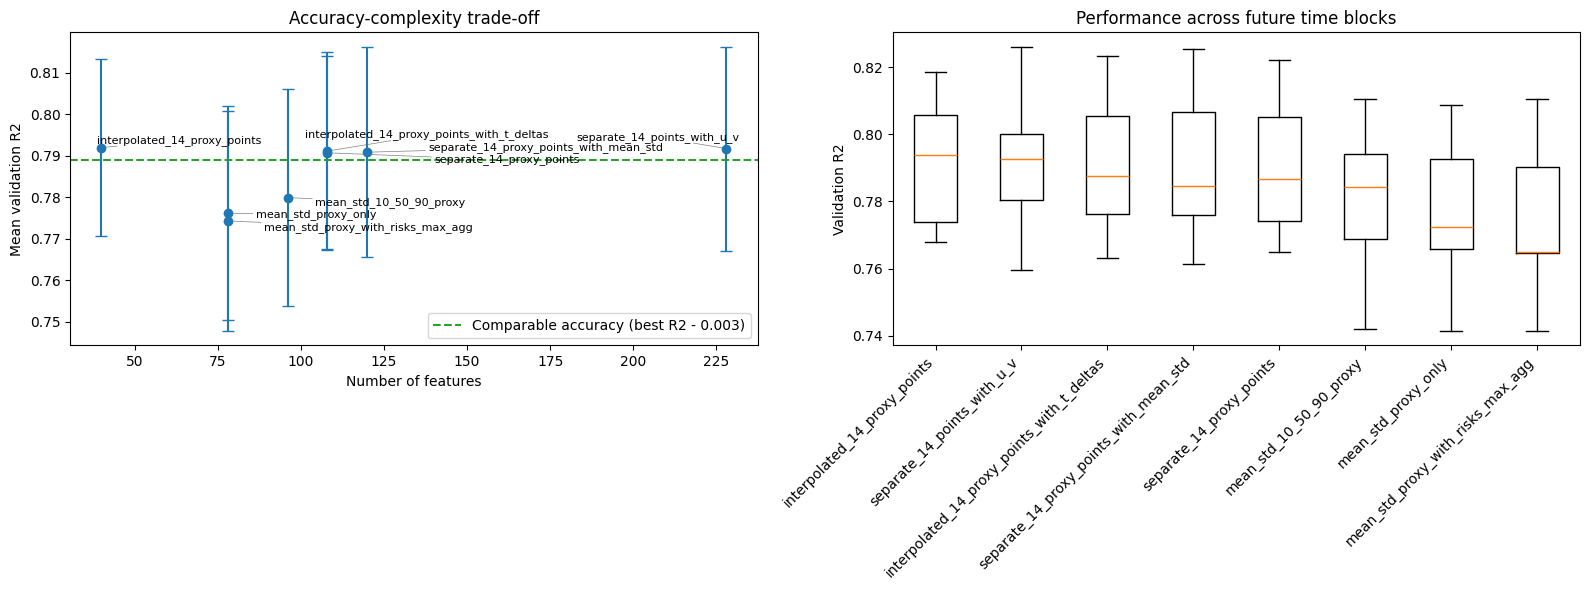

In [8]:
# Import the adjustText library for automatic label adjustment in plots
from adjustText import adjust_text

plot_order = dataset_summary.sort_values("val_r2_mean", ascending=False)["dataset"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot of mean validation R2 vs. number of features with error bars
axes[0].errorbar(
    dataset_summary["n_features"],
    dataset_summary["val_r2_mean"],
    yerr=dataset_summary["val_r2_std"],
    fmt="o",
    capsize=4,
)

# Create text labels for each point in the scatter plot
texts = []
for row in dataset_summary.itertuples():
    texts.append(
        axes[0].text(
            row.n_features,
            row.val_r2_mean,
            row.dataset,
            fontsize=8
        )
    )

# Automatically adjust text labels to avoid overlaps
adjust_text(
    texts, 
    ax=axes[0], 
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5), # тонкие линии-указатели к точкам
    expand=(1.2, 1.4)
)
axes[0].axhline(
    best_mean_r2 - R2_EQUIVALENCE_MARGIN,
    color="tab:green",
    linestyle="--",
    label=f"Comparable accuracy (best R2 - {R2_EQUIVALENCE_MARGIN})",
)
axes[0].set_xlabel("Number of features")
axes[0].set_ylabel("Mean validation R2")
axes[0].set_title("Accuracy-complexity trade-off")
axes[0].legend()

boxplot_values = [
    dataset_fold_scores.loc[
        dataset_fold_scores["dataset"].eq(dataset_name), "val_r2"
    ].to_numpy()
    for dataset_name in plot_order
]
axes[1].boxplot(boxplot_values, tick_labels=plot_order)
axes[1].tick_params(axis="x", labelrotation=45)
for label in axes[1].get_xticklabels():
    label.set_horizontalalignment("right")
axes[1].set_ylabel("Validation R2")
axes[1].set_title("Performance across future time blocks")

plt.tight_layout()
plt.show()

### Final recommendation

The next cell applies the documented decision rule and prints the recommended feature set. It also reports the raw accuracy leader separately, making the accuracy-versus-complexity trade-off transparent.

Results may vary slightly depending on the choice of random seed, but the general ranking and performance of the feature sets remain virtually unchanged.

In [9]:
accuracy_leader = dataset_summary.iloc[0]
recommended_row = dataset_summary.loc[
    dataset_summary["dataset"].eq(recommended_dataset)
].iloc[0]

print(
    "Accuracy leader:\n"
    f"  {accuracy_leader['dataset']} | "
    f"features={int(accuracy_leader['n_features'])} | "
    f"mean R2={accuracy_leader['val_r2_mean']:.4f} | "
    f"mean RMSE={accuracy_leader['val_rmse_mean']:.4f}\n"
)
print(
    "Recommended accuracy-complexity trade-off:\n"
    f"  {recommended_row['dataset']} | "
    f"features={int(recommended_row['n_features'])} | "
    f"mean R2={recommended_row['val_r2_mean']:.4f} | "
    f"R2 gap to leader={recommended_row['r2_gap_to_best']:.4f}"
)

Accuracy leader:
  interpolated_14_proxy_points | features=40 | mean R2=0.7920 | mean RMSE=0.0983

Recommended accuracy-complexity trade-off:
  interpolated_14_proxy_points | features=40 | mean R2=0.7920 | R2 gap to leader=0.0000


### What this experiment establishes

The selected dataset is the strongest candidate for the next research stage, but the scores above are not a final production estimate. After feature-set selection, the next validation notebook should reproduce the intended deployment cycle explicitly:

- Compare different sliding window sizes (60/90/180/365 days) — representing the amount of historical data the model will use for training in production;
- Compare different validation window sizes (1/7/14/30 days) — representing the frequency at which the model will be retrained on the latest data in production;
- Analyze which configurations demonstrate the greatest stability while maintaining high accuracy.

That future experiment should keep the same point-in-time purge used here and should reserve a final untouched period for the last model assessment.